# TOPIC :
### Analysing the Association of Age and Sex with Diabetes Occurrence: An Exploratory Data Analysis Using the CDC Diabetes Health Indicators Dataset

Section 1 — Import and load the dataset

In [126]:
!pip install ucimlrepo

In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from scipy.stats import chi2_contingency

In [128]:
cdc_diabetes = fetch_ucirepo(id=891)

X = cdc_diabetes.data.features
y = cdc_diabetes.data.targets

df = pd.concat([X, y], axis=1)

df.shape

(253680, 22)

Section 2 — Understand the dataset

In [129]:
df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [130]:
df.tail()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
253675,1,1,1,45,0,0,0,0,1,1,...,0,3,0,5,0,1,5,6,7,0
253676,1,1,1,18,0,0,0,0,0,0,...,0,4,0,0,1,0,11,2,4,1
253677,0,0,1,28,0,0,0,1,1,0,...,0,1,0,0,0,0,2,5,2,0
253678,1,0,1,23,0,0,0,0,1,1,...,0,3,0,0,0,1,7,5,1,0
253679,1,1,1,25,0,0,1,1,1,0,...,0,2,0,0,0,0,9,6,2,1


In [131]:
df.columns

Index(['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke',
       'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income',
       'Diabetes_binary'],
      dtype='object')

In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   HighBP                253680 non-null  int64
 1   HighChol              253680 non-null  int64
 2   CholCheck             253680 non-null  int64
 3   BMI                   253680 non-null  int64
 4   Smoker                253680 non-null  int64
 5   Stroke                253680 non-null  int64
 6   HeartDiseaseorAttack  253680 non-null  int64
 7   PhysActivity          253680 non-null  int64
 8   Fruits                253680 non-null  int64
 9   Veggies               253680 non-null  int64
 10  HvyAlcoholConsump     253680 non-null  int64
 11  AnyHealthcare         253680 non-null  int64
 12  NoDocbcCost           253680 non-null  int64
 13  GenHlth               253680 non-null  int64
 14  MentHlth              253680 non-null  int64
 15  PhysHlth              253680 non-n

In [133]:
df.describe()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,0.811420,...,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875,0.139333
std,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,0.391175,...,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148,0.346294
min,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000,0.000000
50%,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000,0.000000
75%,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000,0.000000
max,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000,1.000000


In [134]:
df["Diabetes_binary"].value_counts()

,count
Diabetes_binary,
0,218334
1,35346


In [135]:
df["Diabetes_binary"].value_counts(normalize=True) * 100

,proportion
Diabetes_binary,
0,86.066698
1,13.933302


Section 3 — Data preprocessing

In [136]:
df.isnull().sum()

,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0
Veggies,0


In [137]:
df.duplicated().sum()

np.int64(24206)

In [138]:
df.nunique()

,0
HighBP,2
HighChol,2
CholCheck,2
BMI,84
Smoker,2
Stroke,2
HeartDiseaseorAttack,2
PhysActivity,2
Fruits,2
Veggies,2


In [139]:
age_mapping = {
    1: "18-24",
    2: "25-29",
    3: "30-34",
    4: "35-39",
    5: "40-44",
    6: "45-49",
    7: "50-54",
    8: "55-59",
    9: "60-64",
    10: "65-69",
    11: "70-74",
    12: "75-79",
    13: "80+"
}

age_order = [
    "18-24", "25-29", "30-34", "35-39",
    "40-44", "45-49", "50-54", "55-59",
    "60-64", "65-69", "70-74", "75-79", "80+"
]

df["Age_Group"] = pd.Categorical(
    df["Age"].map(age_mapping),
    categories=age_order,
    ordered=True
)
df[["Age", "Age_Group"]].head()

,Age,Age_Group
0,9,60-64
1,7,50-54
2,9,60-64
3,11,70-74
4,11,70-74


In [140]:
sex_mapping = {
    0: "Female",
    1: "Male"
}

df["Sex_Label"] = df["Sex"].map(sex_mapping)

df["Sex_Label"].value_counts()

,count
Sex_Label,
Female,141974
Male,111706


In [141]:
df["BMI_Category"] = pd.cut(
    df["BMI"],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese"],
    right=False
)

df["BMI_Category"].value_counts()

,count
BMI_Category,
Overweight,93749
Obese,87851
Normal,68953
Underweight,3127


In [142]:
df[
    [
        "Age", "Age_Group",
        "Sex", "Sex_Label",
        "BMI", "BMI_Category",
        "Diabetes_binary"
    ]
].head()

,Age,Age_Group,Sex,Sex_Label,BMI,BMI_Category,Diabetes_binary
0,9,60-64,0,Female,40,Obese,0
1,7,50-54,0,Female,25,Overweight,0
2,9,60-64,0,Female,28,Overweight,0
3,11,70-74,0,Female,27,Overweight,0
4,11,70-74,0,Female,24,Normal,0


Section 4 — Exploratory data analysis

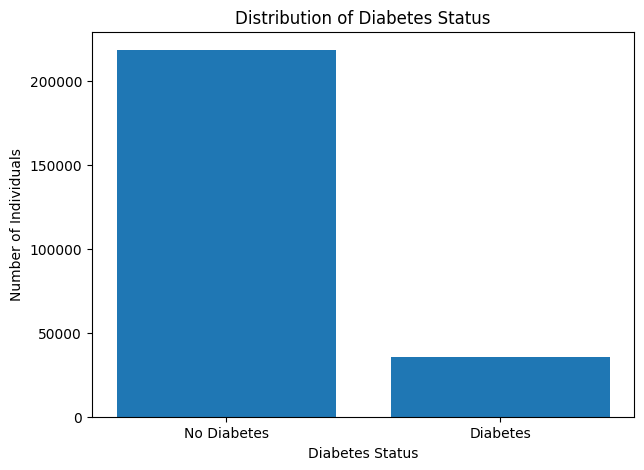

In [143]:
diabetes_counts = df["Diabetes_binary"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Diabetes", "Diabetes"],
    diabetes_counts.values
)
plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Individuals")
plt.show()

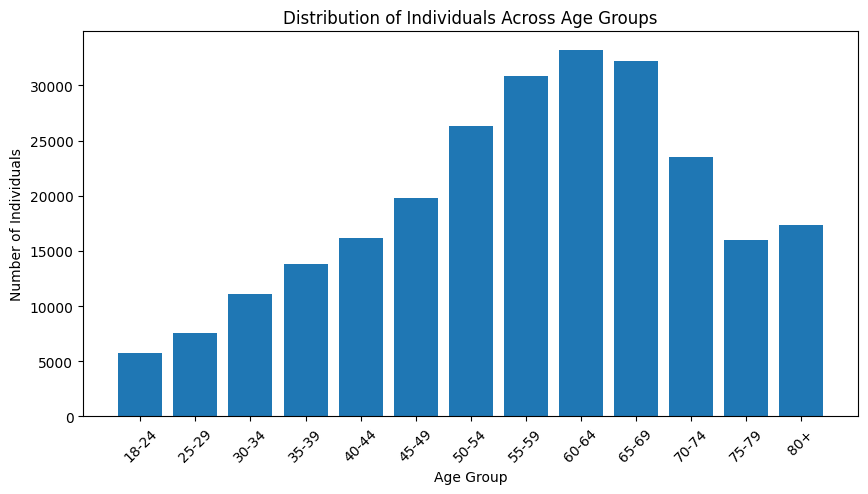

In [144]:
age_counts = df["Age_Group"].value_counts().reindex(age_order)

plt.figure(figsize=(10, 5))
plt.bar(age_order, age_counts.values)
plt.title("Distribution of Individuals Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=45)
plt.show()

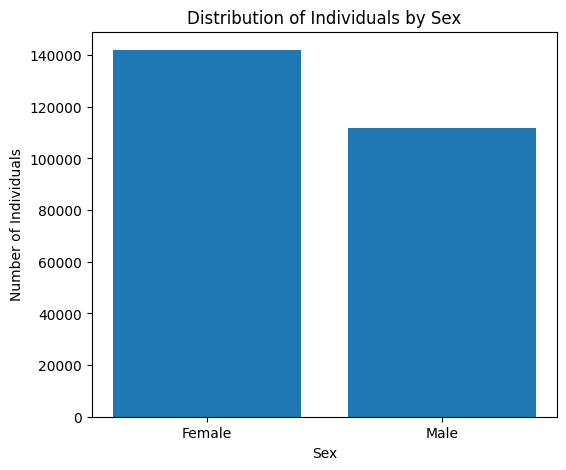

In [145]:
sex_counts = df["Sex_Label"].value_counts()
plt.figure(figsize=(6, 5))
plt.bar(sex_counts.index, sex_counts.values)
plt.title("Distribution of Individuals by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Individuals")
plt.show()

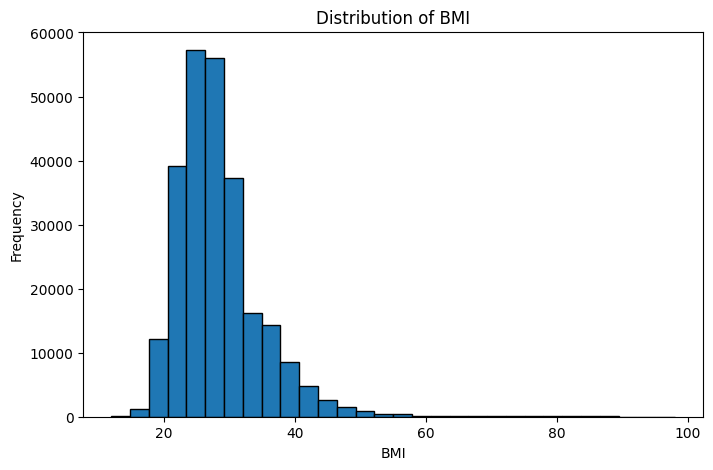

In [146]:
plt.figure(figsize=(8, 5))
plt.hist(df["BMI"], bins=30, edgecolor="black")
plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

In [147]:
df["BMI"].describe()

,BMI
count,253680.000000
mean,28.382364
std,6.608694
min,12.000000
25%,24.000000
50%,27.000000
75%,31.000000
max,98.000000


Section 5 — Age and diabetes

In [148]:
age_diabetes_counts = df.groupby(
    ["Age_Group", "Diabetes_binary"],
    observed=True
).size().unstack(fill_value=0)

age_diabetes_counts

Diabetes_binary,0,1
Age_Group,,
18-24,5622,78
25-29,7458,140
30-34,10809,314
35-39,13197,626
40-44,15106,1051
45-49,18077,1742
50-54,23226,3088
55-59,26569,4263
60-64,27511,5733


In [149]:
age_diabetes_percentage = (
    age_diabetes_counts[1] /
    age_diabetes_counts.sum(axis=1)
) * 100

age_diabetes_percentage

,0
Age_Group,
18-24,1.368421
25-29,1.842590
30-34,2.822979
35-39,4.528684
40-44,6.504920
45-49,8.789545
50-54,11.735198
55-59,13.826544
60-64,17.245217


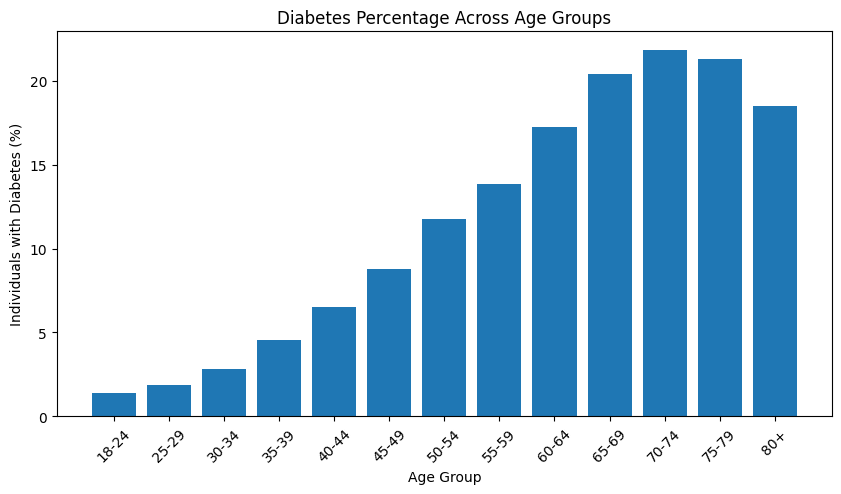

In [150]:
plt.figure(figsize=(10, 5))
plt.bar(
    age_diabetes_percentage.index.astype(str),
    age_diabetes_percentage.values
)
plt.title("Diabetes Percentage Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Individuals with Diabetes (%)")
plt.xticks(rotation=45)
plt.show()

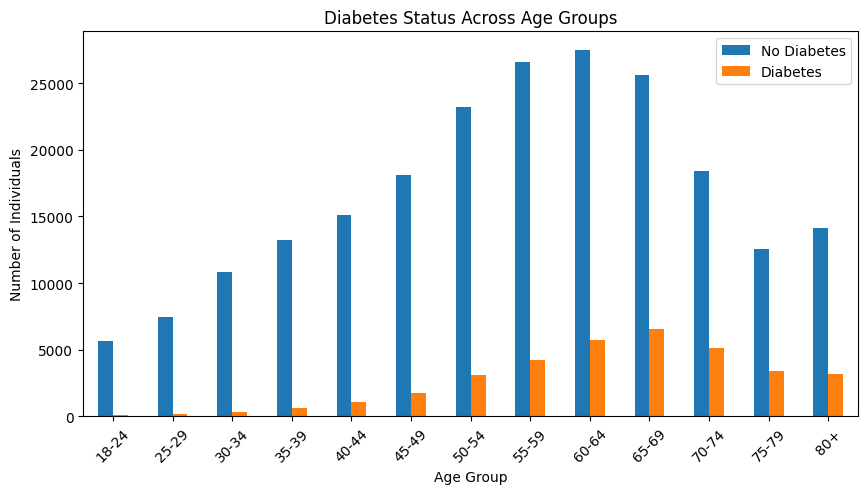

In [151]:
age_diabetes_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Diabetes Status Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=45)
plt.legend(["No Diabetes", "Diabetes"])
plt.show()

In [152]:
age_diabetes_percentage.sort_values(ascending=False).head(1)

,0
Age_Group,
70-74,21.845918


Section 6 — Sex and diabetes

In [153]:
sex_diabetes_counts = df.groupby(
    ["Sex_Label", "Diabetes_binary"],
    observed=True
).size().unstack(fill_value=0)

sex_diabetes_counts

Diabetes_binary,0,1
Sex_Label,,
Female,123563,18411
Male,94771,16935


In [154]:
sex_diabetes_percentage = (
    sex_diabetes_counts[1] /
    sex_diabetes_counts.sum(axis=1)
) * 100

sex_diabetes_percentage

,0
Sex_Label,
Female,12.967867
Male,15.160332


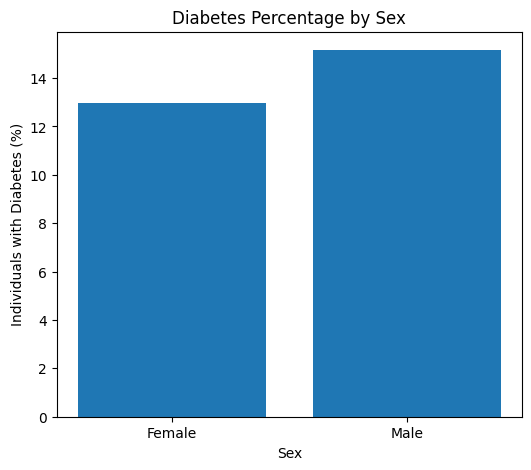

In [155]:
plt.figure(figsize=(6, 5))
plt.bar(
    sex_diabetes_percentage.index,
    sex_diabetes_percentage.values
)
plt.title("Diabetes Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Individuals with Diabetes (%)")
plt.show()

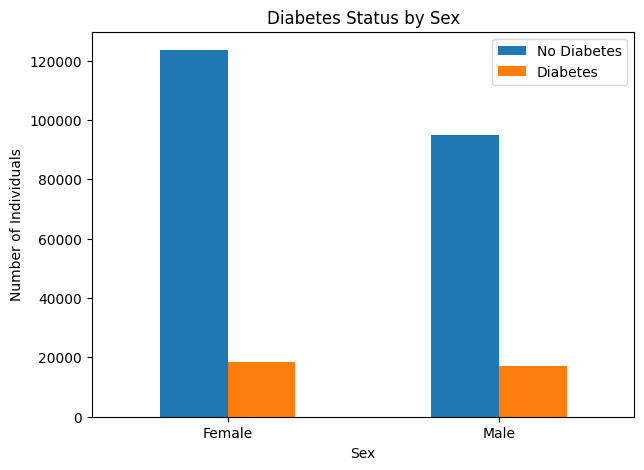

In [156]:
sex_diabetes_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Diabetes Status by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=0)
plt.legend(["No Diabetes", "Diabetes"])
plt.show()

In [157]:
sex_diabetes_percentage

,0
Sex_Label,
Female,12.967867
Male,15.160332


Section 7 — Combined age and sex analysis

In [158]:
age_sex_diabetes = df.groupby(
    ["Age_Group", "Sex_Label"],
    observed=True
)["Diabetes_binary"].mean() * 100

age_sex_diabetes

Age_Group  Sex_Label
18-24      Female        1.639344
           Male          1.116751
25-29      Female        2.230018
           Male          1.413917
30-34      Female        3.150775
           Male          2.430350
35-39      Female        4.737864
           Male          4.263693
40-44      Female        6.304729
           Male          6.765418
45-49      Female        8.254026
           Male          9.447756
50-54      Female       11.090848
           Male         12.564080
55-59      Female       12.908581
           Male         15.026566
60-64      Female       16.244322
           Male         18.466573
65-69      Female       18.317083
           Male         22.891149
70-74      Female       19.401170
           Male         24.946983
75-79      Female       19.473349
           Male         23.910393
80+        Female       16.536780
           Male         21.473469
Name: Diabetes_binary, dtype: float64

In [159]:
age_sex_comparison = age_sex_diabetes.unstack()

age_sex_comparison

Sex_Label,Female,Male
Age_Group,,
18-24,1.639344,1.116751
25-29,2.230018,1.413917
30-34,3.150775,2.430350
35-39,4.737864,4.263693
40-44,6.304729,6.765418
45-49,8.254026,9.447756
50-54,11.090848,12.564080
55-59,12.908581,15.026566
60-64,16.244322,18.466573


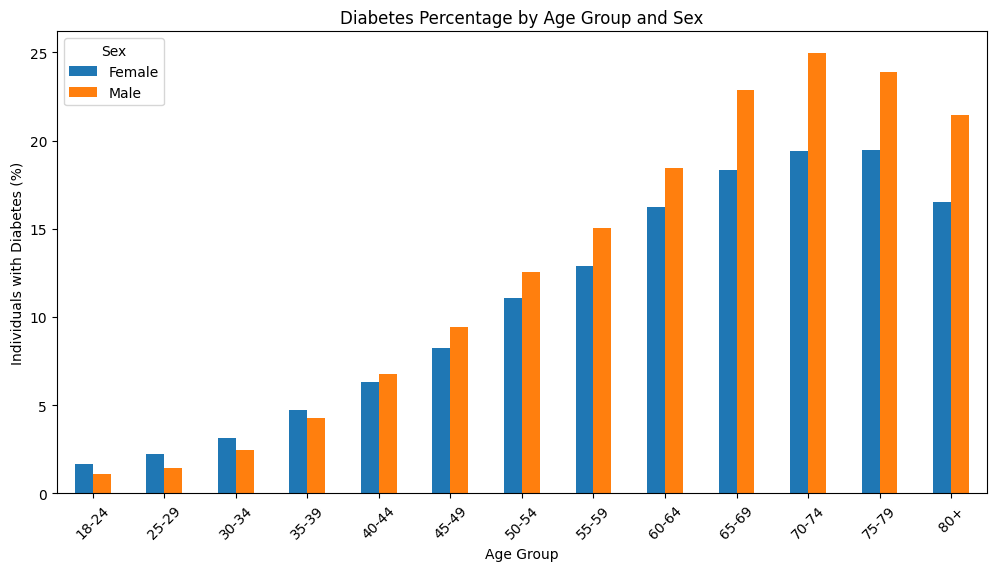

In [160]:
age_sex_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Diabetes Percentage by Age Group and Sex")
plt.xlabel("Age Group")
plt.ylabel("Individuals with Diabetes (%)")
plt.xticks(rotation=45)
plt.legend(title="Sex")
plt.show()

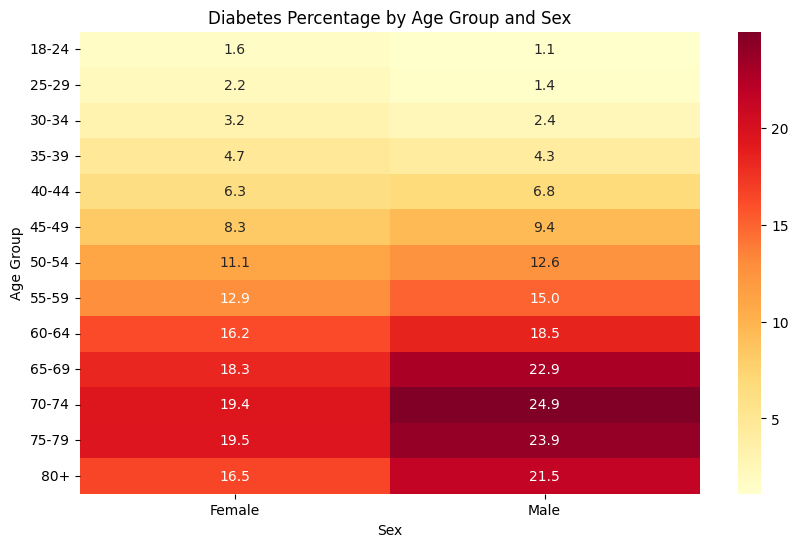

In [161]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    age_sex_comparison,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Diabetes Percentage by Age Group and Sex")
plt.xlabel("Sex")
plt.ylabel("Age Group")
plt.show()

Section 8 — BMI and diabetes

In [162]:
df.groupby("Diabetes_binary")["BMI"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Diabetes_binary,,,,
0,27.805770,27.0,12,98
1,31.944011,31.0,13,98


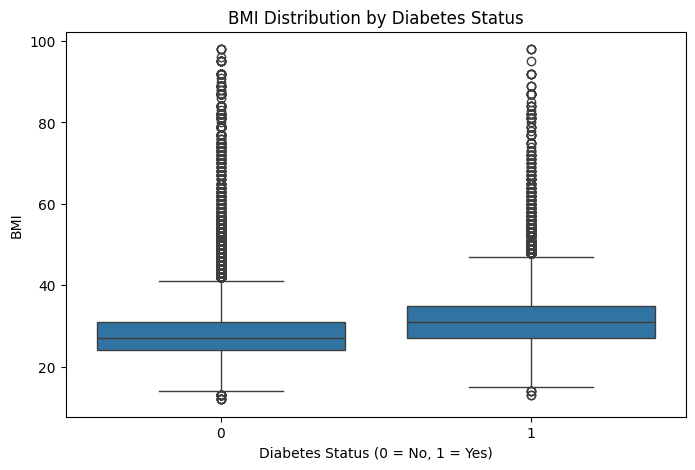

In [163]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Diabetes_binary",
    y="BMI"
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("BMI")
plt.show()

In [164]:
bmi_diabetes_counts = df.groupby(
    ["BMI_Category", "Diabetes_binary"],
    observed=True
).size().unstack(fill_value=0)

bmi_diabetes_percentage = (
    bmi_diabetes_counts[1] /
    bmi_diabetes_counts.sum(axis=1)
) * 100

bmi_diabetes_percentage

,0
BMI_Category,
Underweight,5.404541
Normal,5.696634
Overweight,11.404922
Obese,23.399847


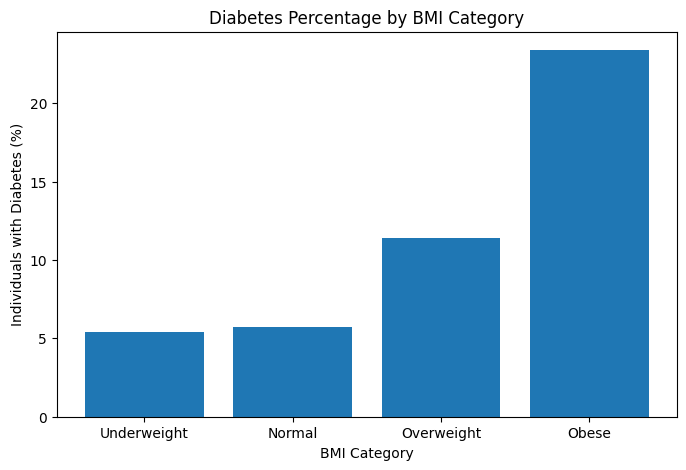

In [165]:
plt.figure(figsize=(8, 5))

plt.bar(
    bmi_diabetes_percentage.index.astype(str),
    bmi_diabetes_percentage.values
)

plt.title("Diabetes Percentage by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Individuals with Diabetes (%)")
plt.show()

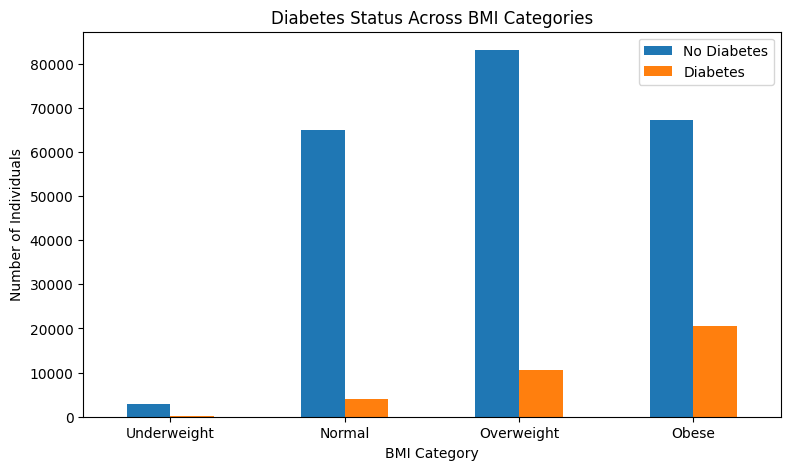

In [166]:
bmi_diabetes_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetes Status Across BMI Categories")
plt.xlabel("BMI Category")
plt.ylabel("Number of Individuals")
plt.xticks(rotation=0)
plt.legend(["No Diabetes", "Diabetes"])
plt.show()

Section 9 — Other health indicators

In [167]:
highbp_counts = df.groupby(
    ["HighBP", "Diabetes_binary"],
    observed=True
).size().unstack(fill_value=0)

highbp_percentage = (
    highbp_counts[1] /
    highbp_counts.sum(axis=1)
) * 100

highbp_percentage

,0
HighBP,
0,6.035167
1,24.445690


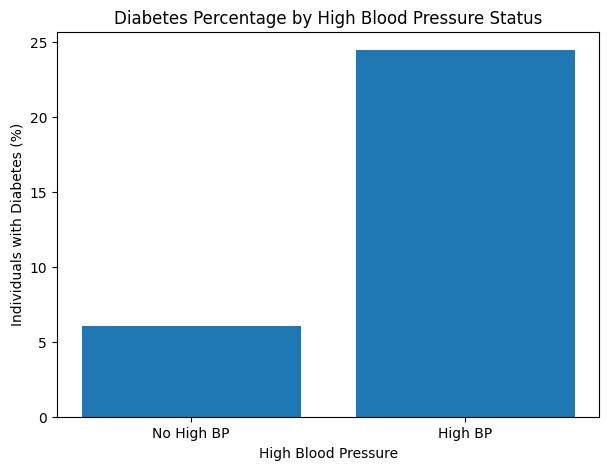

In [168]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["No High BP", "High BP"],
    highbp_percentage.values
)

plt.title("Diabetes Percentage by High Blood Pressure Status")
plt.xlabel("High Blood Pressure")
plt.ylabel("Individuals with Diabetes (%)")
plt.show()

In [169]:
highchol_counts = df.groupby(
    ["HighChol", "Diabetes_binary"],
    observed=True
).size().unstack(fill_value=0)

highchol_percentage = (
    highchol_counts[1] /
    highchol_counts.sum(axis=1)
) * 100

highchol_percentage

,0
HighChol,
0,7.981436
1,22.014853


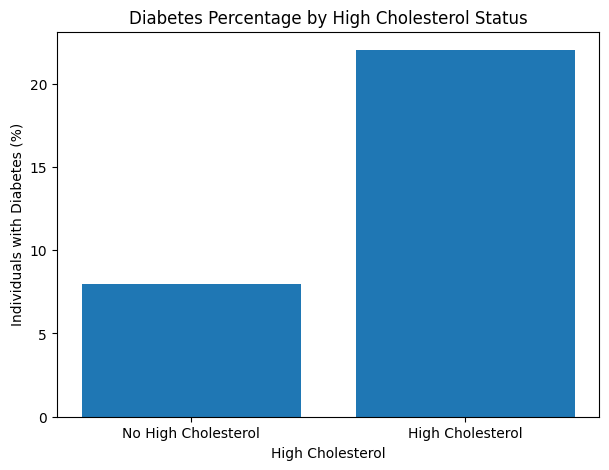

In [170]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["No High Cholesterol", "High Cholesterol"],
    highchol_percentage.values
)

plt.title("Diabetes Percentage by High Cholesterol Status")
plt.xlabel("High Cholesterol")
plt.ylabel("Individuals with Diabetes (%)")
plt.show()

In [171]:
selected_columns = [
    "Age",
    "Sex",
    "BMI",
    "HighBP",
    "HighChol",
    "Diabetes_binary"
]

correlation_matrix = df[selected_columns].corr()

correlation_matrix

,Age,Sex,BMI,HighBP,HighChol,Diabetes_binary
Age,1.000000,-0.027340,-0.036618,0.344452,0.272318,0.177442
Sex,-0.027340,1.000000,0.042950,0.052207,0.031205,0.031430
BMI,-0.036618,0.042950,1.000000,0.213748,0.106722,0.216843
HighBP,0.344452,0.052207,0.213748,1.000000,0.298199,0.263129
HighChol,0.272318,0.031205,0.106722,0.298199,1.000000,0.200276
Diabetes_binary,0.177442,0.031430,0.216843,0.263129,0.200276,1.000000


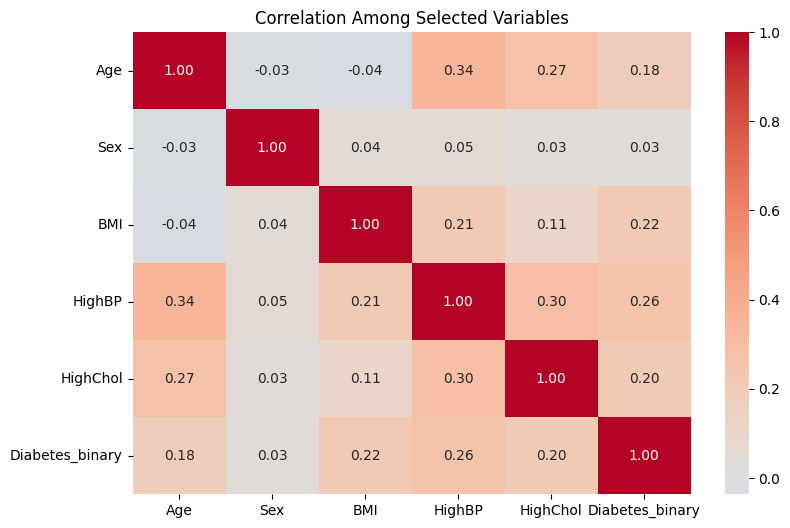

In [172]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Among Selected Variables")
plt.show()

Section 10 — Chi-square association tests

In [173]:
def chi_square_test(data, variable):

    table = data.groupby(
        [variable, "Diabetes_binary"],
        observed=True
    ).size().unstack(fill_value=0)

    chi2, p_value, dof, expected = chi2_contingency(table)

    return {
        "Variable": variable,
        "Chi-square": chi2,
        "Degrees of Freedom": dof,
        "P-value": p_value
    }

In [174]:
age_chi_square = chi_square_test(df, "Age_Group")
pd.DataFrame([age_chi_square])

,Variable,Chi-square,Degrees of Freedom,P-value
0,Age_Group,8795.050614,12,0.0


In [175]:
sex_chi_square = chi_square_test(df, "Sex_Label")

pd.DataFrame([sex_chi_square])

,Variable,Chi-square,Degrees of Freedom,P-value
0,Sex_Label,250.413668,1,2.109875e-56


In [176]:
bmi_chi_square = chi_square_test(df, "BMI_Category")

pd.DataFrame([bmi_chi_square])

,Variable,Chi-square,Degrees of Freedom,P-value
0,BMI_Category,11155.445006,3,0.0


In [177]:
highbp_chi_square = chi_square_test(df, "HighBP")

pd.DataFrame([highbp_chi_square])

,Variable,Chi-square,Degrees of Freedom,P-value
0,HighBP,17562.44609,1,0.0


In [178]:
highchol_chi_square = chi_square_test(df, "HighChol")

pd.DataFrame([highchol_chi_square])

,Variable,Chi-square,Degrees of Freedom,P-value
0,HighChol,10174.074889,1,0.0


In [179]:
variables_to_test = [
    "Age_Group",
    "Sex_Label",
    "BMI_Category",
    "HighBP",
    "HighChol"
]

chi_square_results = [
    chi_square_test(df, variable)
    for variable in variables_to_test
]

final_statistics = pd.DataFrame(chi_square_results)

final_statistics

,Variable,Chi-square,Degrees of Freedom,P-value
0,Age_Group,8795.050614,12,0.000000e+00
1,Sex_Label,250.413668,1,2.109875e-56
2,BMI_Category,11155.445006,3,0.000000e+00
3,HighBP,17562.446090,1,0.000000e+00
4,HighChol,10174.074889,1,0.000000e+00


In [180]:
final_statistics["Significance"] = np.where(
    final_statistics["P-value"] < 0.05,
    "Statistically Significant",
    "Not Statistically Significant"
)

final_statistics

,Variable,Chi-square,Degrees of Freedom,P-value,Significance
0,Age_Group,8795.050614,12,0.000000e+00,Statistically Significant
1,Sex_Label,250.413668,1,2.109875e-56,Statistically Significant
2,BMI_Category,11155.445006,3,0.000000e+00,Statistically Significant
3,HighBP,17562.446090,1,0.000000e+00,Statistically Significant
4,HighChol,10174.074889,1,0.000000e+00,Statistically Significant


Section 11 — Strength of association using Cramer’s V

In [181]:
def cramers_v(data, variable):
    table = data.groupby(
        [variable, "Diabetes_binary"],
        observed=True
    ).size().unstack(fill_value=0)

    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    rows, columns = table.shape

    return np.sqrt(
        chi2 / (n * min(rows - 1, columns - 1))
    )

In [182]:
association_results = [
    {
        "Variable": variable,
        "Cramers_V": cramers_v(df, variable)
    }
    for variable in variables_to_test
]

association_df = pd.DataFrame(association_results)
association_df

,Variable,Cramers_V
0,Age_Group,0.186198
1,Sex_Label,0.031419
2,BMI_Category,0.209701
3,HighBP,0.263117
4,HighChol,0.200265


In [183]:
final_statistics = final_statistics.merge(
    association_df,
    on="Variable"
)

final_statistics = final_statistics.sort_values(
    by="Cramers_V",
    ascending=False
)

final_statistics

,Variable,Chi-square,Degrees of Freedom,P-value,Significance,Cramers_V
3,HighBP,17562.446090,1,0.000000e+00,Statistically Significant,0.263117
2,BMI_Category,11155.445006,3,0.000000e+00,Statistically Significant,0.209701
4,HighChol,10174.074889,1,0.000000e+00,Statistically Significant,0.200265
0,Age_Group,8795.050614,12,0.000000e+00,Statistically Significant,0.186198
1,Sex_Label,250.413668,1,2.109875e-56,Statistically Significant,0.031419


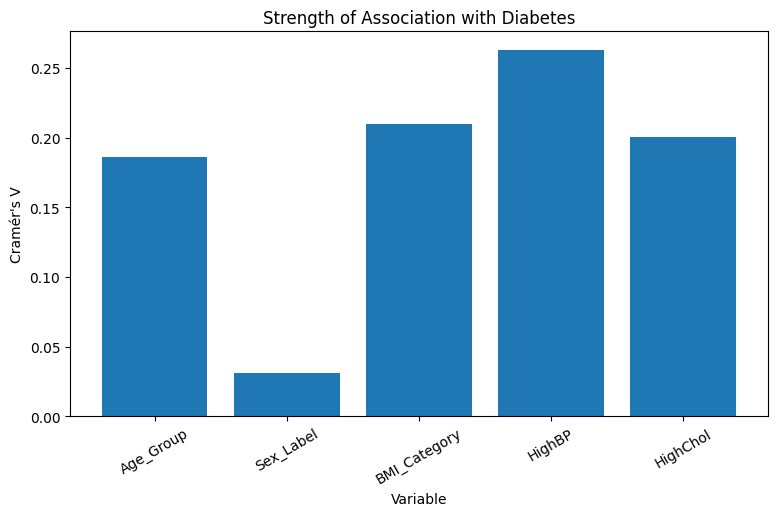

In [184]:
plt.figure(figsize=(9, 5))
plt.bar(association_df["Variable"],association_df["Cramers_V"])
plt.title("Strength of Association with Diabetes")
plt.xlabel("Variable")
plt.ylabel("Cramér's V")
plt.xticks(rotation=30)
plt.show()

In [185]:
final_statistics["P-value (display)"] = final_statistics[
    "P-value"
].apply(
    lambda p: "< 0.001" if p < 0.001 else f"{p:.4f}"
)

final_statistics

,Variable,Chi-square,Degrees of Freedom,P-value,Significance,Cramers_V,P-value (display)
3,HighBP,17562.446090,1,0.000000e+00,Statistically Significant,0.263117,< 0.001
2,BMI_Category,11155.445006,3,0.000000e+00,Statistically Significant,0.209701,< 0.001
4,HighChol,10174.074889,1,0.000000e+00,Statistically Significant,0.200265,< 0.001
0,Age_Group,8795.050614,12,0.000000e+00,Statistically Significant,0.186198,< 0.001
1,Sex_Label,250.413668,1,2.109875e-56,Statistically Significant,0.031419,< 0.001


Section 12 — Overall findings

In [186]:
findings = pd.DataFrame({
    "Age Group": age_diabetes_percentage,
    "Female (%)": age_sex_comparison["Female"],
    "Male (%)": age_sex_comparison["Male"]
})

findings

,Age Group,Female (%),Male (%)
Age_Group,,,
18-24,1.368421,1.639344,1.116751
25-29,1.842590,2.230018,1.413917
30-34,2.822979,3.150775,2.430350
35-39,4.528684,4.737864,4.263693
40-44,6.504920,6.304729,6.765418
45-49,8.789545,8.254026,9.447756
50-54,11.735198,11.090848,12.564080
55-59,13.826544,12.908581,15.026566
60-64,17.245217,16.244322,18.466573


## Conclusion

In this project, I analysed the relationship between age, sex and diabetes using the CDC Diabetes Health Indicators dataset. I compared diabetes percentages across different age groups and between males and females. I also studied BMI, high blood pressure and high cholesterol to understand how they were associated with diabetes.

From the analysis, high blood pressure showed the strongest association with diabetes among the variables studied, while sex showed the weakest association. The Chi-square test and Cramér's V helped me examine these relationships and compare their strength.

This analysis helped me understand how data analysis and visualisation can be used to study health-related data. However, the results show associations only and do not prove that any of these factors cause diabetes.

Section 13 — Download the analysed CSV

In [187]:
df.to_csv("analysed_diabetes_dataset.csv", index=False)

from google.colab import files
files.download("analysed_diabetes_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>